In [ ]:

# Check if GPU is available
import torch
print(f"GPU Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")

# Install required packages

!pip install segmentation-models-pytorch
!pip install albumentations==1.3.1
!pip install opencv-python-headless
!pip install plotly
!pip install nibabel  # For NIfTI medical image format
!pip install SimpleITK  # For medical image processing
!pip install scikit-image



🚀 Setting up Cardiac Segmentation Environment...
GPU Available: True
GPU Device: Tesla T4
GPU Memory: 14.7 GB

📦 Installing required packages...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 39.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 28.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.7/188.7 

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Deep Learning
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms as transforms

# Segmentation Models
import segmentation_models_pytorch as smp

# Image Processing
import cv2
import albumentations as A
from albumentations.pytorch import ToTensorV2
import nibabel as nib
import SimpleITK as sitk
from skimage import transform, measure

# Visualization
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

# Metrics
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import KFold

print("All libraries imported successfully!")

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

📚 All libraries imported successfully!


In [ ]:

import os
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Navigate to project directory (note: no space in "My Drive")
project_path = '/content/drive/MyDrive/Cardiac_Segmentation_Project'
os.makedirs(project_path, exist_ok=True)
os.chdir(project_path)

print(f"Setup complete! Working in: {os.getcwd()}")

Mounted at /content/drive
✅ Setup complete! Working in: /content/drive/MyDrive/Cardiac_Segmentation_Project


In [ ]:
import os
import shutil
from pathlib import Path
import subprocess

# Install unrar tool

!apt-get update -qq
!apt-get install -qq unrar

# Check if the RAR file exists
rar_path = "/content/drive/MyDrive/Cardiac_Segmentation_Project/MnM2.rar"
if os.path.exists(rar_path):
    file_size = os.path.getsize(rar_path) / (1024**2)  # Size in MB
    print(f"Found MnM2.rar ({file_size:.1f} MB)")
else:
    print(f"RAR file not found at: {rar_path}")
    print("Please check the file path and make sure Google Drive is mounted.")

📦 Installing RAR extraction tools...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
✅ Found MnM2.rar (9369.3 MB)


In [ ]:
# CELL 1: Check file and install tools
import os
import shutil
from pathlib import Path
import subprocess

# First, let's check if your RAR file exists and get its info
rar_path = "/content/drive/MyDrive/Cardiac_Segmentation_Project/MnM2.rar"

print("Checking RAR file...")
if os.path.exists(rar_path):
    file_size = os.path.getsize(rar_path) / (1024**2)  # Size in MB
    print(f"Found MnM2.rar")
    print(f"   Path: {rar_path}")
    print(f"   Size: {file_size:.1f} MB")
else:
    print(f"RAR file not found at: {rar_path}")
    print("\nLet's check what's in your directory:")
    drive_dir = "/content/drive/MyDrive/Cardiac_Segmentation_Project/"
    if os.path.exists(drive_dir):
        files = os.listdir(drive_dir)
        print(f"Files found: {files}")
    else:
        print("Directory doesn't exist. Make sure Google Drive is mounted.")

    # Stop here if file not found
    raise FileNotFoundError(f"Please check the file path: {rar_path}")

# Install extraction tools
print("\nInstalling extraction tools...")
try:
    # Try installing unrar
    !apt-get update -qq
    !apt-get install -qq unrar
    print("unrar installed successfully")
except Exception as e:
    print(f"unrar installation issue: {e}")
    # Try alternative
    !apt-get install -qq p7zip-full
    print("p7zip installed as alternative")

🔍 Checking RAR file...
✅ Found MnM2.rar
   Path: /content/drive/MyDrive/Cardiac_Segmentation_Project/MnM2.rar
   Size: 9369.3 MB

📦 Installing extraction tools...
shell-init: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
shell-init: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected
✅ unrar installed successfully


In [ ]:
def extract_with_unrar(rar_path, extract_to):

    try:
        result = subprocess.run([
            'unrar', 'x', rar_path, extract_to, '-y'
        ], capture_output=True, text=True, timeout=300)

        if result.returncode == 0:
            print("Extraction with unrar successful!")
            return True
        else:
            print(f"unrar failed: {result.stderr}")
            return False
    except Exception as e:
        print(f"unrar error: {e}")
        return False

def extract_with_7zip(rar_path, extract_to):
    """Try extracting with 7zip"""
    try:
        result = subprocess.run([
            '7z', 'x', rar_path, f'-o{extract_to}', '-y'
        ], capture_output=True, text=True, timeout=300)

        if result.returncode == 0:
            print("Extraction with 7zip successful!")
            return True
        else:
            print(f"7zip failed: {result.stderr}")
            return False
    except Exception as e:
        print(f"7zip error: {e}")
        return False

# Set extraction directory
extraction_path = "/content/mnms2_extracted"
os.makedirs(extraction_path, exist_ok=True)

print(f"Extracting RAR file...")
print(f"   From: {rar_path}")
print(f"   To: {extraction_path}")

# Try extraction methods in order
extraction_success = False

# Method 1: unrar
print("\nTrying unrar...")
if extract_with_unrar(rar_path, extraction_path):
    extraction_success = True
else:
    # Method 2: 7zip
    print("\nTrying 7zip...")
    if extract_with_7zip(rar_path, extraction_path):
        extraction_success = True

if not extraction_success:
    print("All extraction methods failed!")
    print("Alternative: Try uploading the extracted files manually")
    extraction_path = None
else:
    print(f"Extraction completed!")
    print(f" Files extracted to: {extraction_path}")

🔄 Extracting RAR file...
   From: /content/drive/MyDrive/Cardiac_Segmentation_Project/MnM2.rar
   To: /content/mnms2_extracted

📦 Trying unrar...
✅ Extraction with unrar successful!
✅ Extraction completed!
📁 Files extracted to: /content/mnms2_extracted


In [ ]:
# CELL 1: Explore the extracted dataset structure
import os
import shutil
from pathlib import Path
import numpy as np
import nibabel as nib

# Your extraction was successful, so let's explore what we have
extraction_path = "/content/mnms2_extracted"

def explore_extracted_structure(root_path, max_depth=3):
    """Explore the extracted dataset structure"""

    print(f"Exploring extracted M&Ms-2 dataset structure")
    print(f"Root path: {root_path}\n")

    def print_tree(directory, prefix="", current_depth=0):
        if current_depth >= max_depth:
            return

        try:
            items = sorted(os.listdir(directory))
            dirs = [item for item in items if os.path.isdir(os.path.join(directory, item))]
            files = [item for item in items if os.path.isfile(os.path.join(directory, item))]

            # Print directories first
            for i, dir_name in enumerate(dirs):
                is_last_dir = (i == len(dirs) - 1) and len(files) == 0
                current_prefix = "└── " if is_last_dir else "├── "
                dir_path = os.path.join(directory, dir_name)

                # Count items in directory
                try:
                    item_count = len(os.listdir(dir_path))
                    print(f"{prefix}{current_prefix} {dir_name}/ ({item_count} items)")
                except:
                    print(f"{prefix}{current_prefix} {dir_name}/")

                # Recurse into subdirectory
                extension = "    " if is_last_dir else "│   "
                print_tree(dir_path, prefix + extension, current_depth + 1)

            # Print files (limit to first 10)
            for i, file_name in enumerate(files[:10]):
                is_last = i == len(files) - 1 and i < 9
                current_prefix = "└── " if is_last else "├── "
                file_path = os.path.join(directory, file_name)

                try:
                    file_size = os.path.getsize(file_path) / (1024*1024)  # Size in MB
                    print(f"{prefix}{current_prefix} {file_name} ({file_size:.1f} MB)")
                except:
                    print(f"{prefix}{current_prefix} {file_name}")

            if len(files) > 10:
                print(f"{prefix}    ... and {len(files) - 10} more files")

        except PermissionError:
            print(f"{prefix} Permission denied")
        except Exception as e:
            print(f"{prefix} Error: {e}")

    print_tree(root_path)

# Explore the extracted structure
explore_extracted_structure(extraction_path)

📂 Exploring extracted M&Ms-2 dataset structure
Root path: /content/mnms2_extracted

└── 📁 MnM2/ (3 items)
    ├── 📁 dataset/ (360 items)
    │   ├── 📁 001/ (10 items)
    │   ├── 📁 002/ (10 items)
    │   ├── 📁 003/ (10 items)
    │   ├── 📁 004/ (10 items)
    │   ├── 📁 005/ (10 items)
    │   ├── 📁 006/ (10 items)
    │   ├── 📁 007/ (10 items)
    │   ├── 📁 008/ (10 items)
    │   ├── 📁 009/ (10 items)
    │   ├── 📁 010/ (10 items)
    │   ├── 📁 011/ (10 items)
    │   ├── 📁 012/ (10 items)
    │   ├── 📁 013/ (10 items)
    │   ├── 📁 014/ (10 items)
    │   ├── 📁 015/ (10 items)
    │   ├── 📁 016/ (10 items)
    │   ├── 📁 017/ (10 items)
    │   ├── 📁 018/ (10 items)
    │   ├── 📁 019/ (10 items)
    │   ├── 📁 020/ (10 items)
    │   ├── 📁 021/ (10 items)
    │   ├── 📁 022/ (10 items)
    │   ├── 📁 023/ (10 items)
    │   ├── 📁 024/ (10 items)
    │   ├── 📁 025/ (10 items)
    │   ├── 📁 026/ (10 items)
    │   ├── 📁 027/ (10 items)
    │   ├── 📁 028/ (10 items)
    │   ├── 📁 029/ (10 

In [ ]:

# CELL 1: Properly analyze the CSV file
import pandas as pd
import numpy as np
import os
from pathlib import Path

# Set paths
extraction_path = "/content/mnms2_extracted/MnM2"
dataset_path = "/content/mnms2_extracted/MnM2/dataset"
info_csv_path = os.path.join(extraction_path, "dataset_information.csv")

print("FIXING CSV ANALYSIS")
print("="*30)

# Read and clean the CSV file
if os.path.exists(info_csv_path):
    print("Reading dataset_information.csv...")

    # Read with different approaches to handle potential issues
    try:
        # First, let's examine the file structure
        with open(info_csv_path, 'r') as f:
            first_lines = [f.readline().strip() for _ in range(10)]

        print("First 10 lines of CSV:")
        for i, line in enumerate(first_lines):
            print(f"   {i+1}: {line[:100]}...")  # Show first 100 chars

        # Try reading with pandas
        df_info = pd.read_csv(info_csv_path)
        print(f"\nRaw CSV shape: {df_info.shape}")

        # Check for duplicates and get unique subjects
        print(f"Columns: {list(df_info.columns)}")

        if 'SUBJECT_CODE' in df_info.columns:
            # Get unique subjects only
            df_unique = df_info.drop_duplicates(subset=['SUBJECT_CODE'])
            print(f"After removing duplicates: {df_unique.shape}")

            # Filter to match our actual subjects (1-360)
            actual_subjects = [int(d) for d in os.listdir(dataset_path) if d.isdigit()]
            actual_subjects_set = set(actual_subjects)

            print(f"Actual subjects in dataset folder: {len(actual_subjects)} (range: {min(actual_subjects)}-{max(actual_subjects)})")

            # Filter CSV to only include subjects that exist in our dataset
            df_filtered = df_unique[df_unique['SUBJECT_CODE'].isin(actual_subjects_set)]
            print(f" After filtering to existing subjects: {df_filtered.shape}")

            # Display the filtered data
            print(f"\n CLEANED DATASET INFORMATION:")
            print(f"   Unique subjects: {len(df_filtered)}")
            print(f"   Columns: {list(df_filtered.columns)}")

            print(f"\n First 10 subjects:")
            print(df_filtered.head(10))

            # Analyze pathologies
            if 'DISEASE' in df_filtered.columns:
                disease_counts = df_filtered['DISEASE'].value_counts()
                print(f"\n Disease/Pathology Distribution:")

                pathology_names = {
                    'NOR': 'Normal',
                    'HCM': 'Hypertrophic Cardiomyopathy',
                    'DCM': 'Dilated Cardiomyopathy',
                    'ARV': 'Abnormal Right Ventricle',
                    'RVO': 'Right Ventricular Volume Overload'
                }

                for disease, count in disease_counts.items():
                    full_name = pathology_names.get(disease, disease)
                    percentage = (count / len(df_filtered)) * 100
                    print(f"   {disease} ({full_name}): {count} subjects ({percentage:.1f}%)")

            # Analyze other columns
            other_columns = ['VENDOR', 'SCANNER', 'FIELD']
            for col in other_columns:
                if col in df_filtered.columns:
                    unique_values = df_filtered[col].value_counts()
                    print(f"\n {col} Distribution:")
                    for value, count in unique_values.head(5).items():  # Show top 5
                        print(f"   {value}: {count}")

            # Store the cleaned dataframe
            df_info_clean = df_filtered.copy()

        else:
            print(" SUBJECT_CODE column not found")
            df_info_clean = None

    except Exception as e:
        print(f" Error reading CSV: {e}")
        df_info_clean = None

else:
    print(" dataset_information.csv not found")
    df_info_clean = None

🔧 FIXING CSV ANALYSIS
📊 Reading dataset_information.csv...
📋 First 10 lines of CSV:
   1: SUBJECT_CODE,DISEASE,VENDOR,SCANNER,FIELD...
   2: 1,NOR,GE MEDICAL SYSTEMS,SIGNA EXCITE,1.5...
   3: 2,NOR,GE MEDICAL SYSTEMS,SIGNA EXCITE,1.5...
   4: 3,NOR,GE MEDICAL SYSTEMS,SIGNA EXCITE,1.5...
   5: 4,NOR,GE MEDICAL SYSTEMS,SIGNA EXCITE,1.5...
   6: 5,NOR,GE MEDICAL SYSTEMS,SIGNA EXCITE,1.5...
   7: 6,NOR,GE MEDICAL SYSTEMS,SIGNA EXCITE,1.5...
   8: 7,NOR,GE MEDICAL SYSTEMS,SIGNA EXCITE,1.5...
   9: 8,NOR,GE MEDICAL SYSTEMS,SIGNA EXCITE,1.5...
   10: 9,NOR,GE MEDICAL SYSTEMS,SIGNA EXCITE,1.5...

📊 Raw CSV shape: (1048574, 5)
Columns: ['SUBJECT_CODE', 'DISEASE', 'VENDOR', 'SCANNER', 'FIELD']
📊 After removing duplicates: (361, 5)
📁 Actual subjects in dataset folder: 360 (range: 1-360)
📊 After filtering to existing subjects: (360, 5)

✅ CLEANED DATASET INFORMATION:
   Unique subjects: 360
   Columns: ['SUBJECT_CODE', 'DISEASE', 'VENDOR', 'SCANNER', 'FIELD']

📋 First 10 subjects:
   SUBJECT_CODE 

In [ ]:
# ================================================================
# COMPLETE DIRECTORY MAPPING FIX
# Single cell to diagnose and fix the directory structure issue
# ================================================================

import os
import pandas as pd
import numpy as np
from pathlib import Path

# Set paths
dataset_path = "/content/mnms2_extracted/MnM2/dataset"
info_csv_path = "/content/mnms2_extracted/MnM2/dataset_information.csv"

print(" COMPLETE DIRECTORY MAPPING DIAGNOSIS AND FIX")
print("="*55)

# Step 1: Get actual directories
print(" Step 1: Analyzing actual directories...")
actual_dirs = []
for item in os.listdir(dataset_path):
    item_path = os.path.join(dataset_path, item)
    if os.path.isdir(item_path):
        actual_dirs.append(item)

actual_dirs.sort()
print(f"   Found {len(actual_dirs)} directories")
print(f"   First 10: {actual_dirs[:10]}")
print(f"   Last 10: {actual_dirs[-10:]}")

# Check directory patterns
numeric_dirs = [d for d in actual_dirs if d.isdigit()]
print(f"   Numeric directories: {len(numeric_dirs)}")

if numeric_dirs:
    numeric_values = [int(d) for d in numeric_dirs]
    print(f"   Range: {min(numeric_values)} to {max(numeric_values)}")

# Step 2: Re-read and clean CSV
print(f"\n Step 2: Re-reading CSV data...")
if os.path.exists(info_csv_path):
    df_info = pd.read_csv(info_csv_path)
    df_info_clean = df_info.drop_duplicates(subset=['SUBJECT_CODE'])

    # Filter to existing subjects only
    actual_subjects_int = [int(d) for d in actual_dirs if d.isdigit()]
    df_info_clean = df_info_clean[df_info_clean['SUBJECT_CODE'].isin(actual_subjects_int)]

    print(f"   CSV subjects after filtering: {len(df_info_clean)}")
    csv_subjects = sorted(df_info_clean['SUBJECT_CODE'].unique())
    print(f"   CSV subject range: {min(csv_subjects)} to {max(csv_subjects)}")
else:
    print("    CSV file not found")
    df_info_clean = None

# Step 3: Create mapping
print(f"\n Step 3: Creating subject directory mapping...")

subject_mapping = {}

if df_info_clean is not None and numeric_dirs:
    # Try direct mapping first
    for csv_subj in csv_subjects:
        csv_subj_int = int(csv_subj)

        # Try different formats
        possible_dirs = [
            str(csv_subj_int),           # "1", "2", etc.
            f"{csv_subj_int:03d}",       # "001", "002", etc.
            f"{csv_subj_int:02d}",       # "01", "02", etc.
        ]

        for possible_dir in possible_dirs:
            if possible_dir in actual_dirs:
                subject_mapping[csv_subj_int] = possible_dir
                break

    print(f"   Successfully mapped {len(subject_mapping)}/{len(csv_subjects)} subjects")

# Step 4: Test the mapping with actual file access
print(f"\nStep 4: Testing mapping with file access...")

test_subjects = list(subject_mapping.keys())[:5]  # Test first 5
successful_tests = 0

for csv_subj in test_subjects:
    dir_name = subject_mapping[csv_subj]
    dir_path = os.path.join(dataset_path, dir_name)

    # Get pathology
    pathology = 'Unknown'
    if df_info_clean is not None:
        subject_meta = df_info_clean[df_info_clean['SUBJECT_CODE'] == csv_subj]
        if not subject_meta.empty:
            pathology = subject_meta.iloc[0]['DISEASE']

    print(f"\n Testing Subject {csv_subj} → '{dir_name}' ({pathology})")

    if os.path.exists(dir_path):
        try:
            files = os.listdir(dir_path)

            # Classify files
            images = []
            labels = []

            for file in files:
                if file.endswith(('.nii.gz', '.nii')):
                    if any(keyword in file.lower() for keyword in ['gt', 'mask', 'label']):
                        labels.append(file)
                    else:
                        images.append(file)

            print(f"    Success: {len(images)} images, {len(labels)} labels")
            if images:
                print(f"    Sample image: {images[0]}")
            if labels:
                print(f"    Sample label: {labels[0]}")

            successful_tests += 1

        except Exception as e:
            print(f"    Error: {e}")
    else:
        print(f"    Directory not found")

print(f"\n Mapping test results: {successful_tests}/{len(test_subjects)} successful")

# Step 5: Count files by pathology using correct mapping
print(f"\n Step 5: Counting files by pathology (using correct mapping)...")

pathology_stats = {}

if len(subject_mapping) > 0 and df_info_clean is not None:

    print("Processing all subjects...")

    for csv_subj, dir_name in subject_mapping.items():
        dir_path = os.path.join(dataset_path, dir_name)

        # Get pathology
        subject_meta = df_info_clean[df_info_clean['SUBJECT_CODE'] == csv_subj]
        pathology = subject_meta.iloc[0]['DISEASE'] if not subject_meta.empty else 'Unknown'

        # Initialize pathology stats
        if pathology not in pathology_stats:
            pathology_stats[pathology] = {
                'subjects': 0,
                'images': 0,
                'labels': 0
            }

        pathology_stats[pathology]['subjects'] += 1

        # Count files
        if os.path.exists(dir_path):
            try:
                files = os.listdir(dir_path)

                for file in files:
                    if file.endswith(('.nii.gz', '.nii')):
                        if any(keyword in file.lower() for keyword in ['gt', 'mask', 'label']):
                            pathology_stats[pathology]['labels'] += 1
                        else:
                            pathology_stats[pathology]['images'] += 1

            except Exception as e:
                print(f"    Error processing {dir_name}: {e}")

    # Display results
    print(f"\n CORRECTED PATHOLOGY STATISTICS:")
    print(f"{'Pathology':<15} {'Subjects':<10} {'Images':<10} {'Labels':<10}")
    print("-" * 50)

    pathology_names = {
        'NOR': 'Normal',
        'LV': 'Left Ventricle',
        'HCM': 'Hypertrophic CM',
        'ARR': 'Arrhythmia',
        'FALL': 'Fall related',
        'CIA': 'CIA related',
        'RV': 'Right Ventricle',
        'TRI': 'Tricuspid'
    }

    total_subjects = 0
    total_images = 0
    total_labels = 0

    for pathology, stats in sorted(pathology_stats.items()):
        display_name = pathology_names.get(pathology, pathology)
        print(f"{display_name:<15} {stats['subjects']:<10} {stats['images']:<10} {stats['labels']:<10}")

        total_subjects += stats['subjects']
        total_images += stats['images']
        total_labels += stats['labels']

    print("-" * 50)
    print(f"{'TOTAL':<15} {total_subjects:<10} {total_images:<10} {total_labels:<10}")

# Step 6: Recommend pathologies
print(f"\n Step 6: Pathology recommendations for your project...")

if pathology_stats:
    # Sort by subject count
    sorted_pathologies = sorted(pathology_stats.items(), key=lambda x: x[1]['subjects'], reverse=True)

    print(f" Pathologies ranked by subject count:")

    recommended = []
    for pathology, stats in sorted_pathologies:
        full_name = pathology_names.get(pathology, pathology)
        subject_count = stats['subjects']

        if subject_count >= 20:
            status = " Highly recommended"
            recommended.append(pathology)
        elif subject_count >= 15:
            status = " Recommended"
            recommended.append(pathology)
        else:
            status = " Limited samples"

        print(f"   {pathology} ({full_name}): {subject_count} subjects - {status}")

    # Final recommendation
    print(f"\n💡 FINAL RECOMMENDATION:")
    if len(recommended) >= 2:
        selected = recommended[:3]  # Top 3
        print(f"   Select: {selected}")

        total_subjects = sum(pathology_stats[p]['subjects'] for p in selected)
        total_images = sum(pathology_stats[p]['images'] for p in selected)
        total_labels = sum(pathology_stats[p]['labels'] for p in selected)

        print(f"   Total: {total_subjects} subjects, {total_images} images, {total_labels} labels")
        print(f"    Excellent dataset size for robust training!")
    else:
        print(f"    Limited high-sample pathologies available")

# Step 7: Store results for next steps
print(f"\n Step 7: Storing results for next steps...")

# Store key variables for future use
globals_to_store = {
    'subject_mapping': subject_mapping,
    'pathology_stats': pathology_stats,
    'df_info_clean': df_info_clean,
    'dataset_path': dataset_path
}

print("    Key variables stored:")
for var_name, var_value in globals_to_store.items():
    if var_value is not None:
        if isinstance(var_value, dict):
            print(f"     {var_name}: {len(var_value)} items")
        elif isinstance(var_value, pd.DataFrame):
            print(f"     {var_name}: {len(var_value)} rows")
        else:
            print(f"     {var_name}: {type(var_value)}")

print(f"\n DIRECTORY MAPPING FIXED!")
print("="*30)
print("Successfully mapped CSV subjects to actual directories")
print("Verified file access and counted images/labels")
print("Generated pathology statistics")
print("Ready for dataset organization")

print(f"\nNext steps:")
print("   1. Select your pathologies based on the recommendations above")
print("   2. Create train/validation/test splits")
print("   3. Organize files for deep learning")
print("   4. Start model training!")

🔧 COMPLETE DIRECTORY MAPPING DIAGNOSIS AND FIX
📁 Step 1: Analyzing actual directories...
   Found 360 directories
   First 10: ['001', '002', '003', '004', '005', '006', '007', '008', '009', '010']
   Last 10: ['351', '352', '353', '354', '355', '356', '357', '358', '359', '360']
   Numeric directories: 360
   Range: 1 to 360

📊 Step 2: Re-reading CSV data...
   CSV subjects after filtering: 360
   CSV subject range: 1.0 to 360.0

🗺️ Step 3: Creating subject directory mapping...
   ✅ Successfully mapped 360/360 subjects

🧪 Step 4: Testing mapping with file access...

📁 Testing Subject 1 → '001' (NOR)
   ✅ Success: 6 images, 4 labels
   🖼️ Sample image: 001_LA_CINE.nii.gz
   🎯 Sample label: 001_SA_ES_gt.nii.gz

📁 Testing Subject 2 → '002' (NOR)
   ✅ Success: 6 images, 4 labels
   🖼️ Sample image: 002_SA_ED.nii.gz
   🎯 Sample label: 002_SA_ED_gt.nii.gz

📁 Testing Subject 3 → '003' (NOR)
   ✅ Success: 6 images, 4 labels
   🖼️ Sample image: 003_LA_ED.nii.gz
   🎯 Sample label: 003_LA_ED_gt.

In [ ]:
# ================================================================
# ORGANIZE FINAL DATASET FOR TRAINING
# Create train/validation/test splits and organize files
# ================================================================

import os
import shutil
import numpy as np
import pandas as pd
from pathlib import Path

print(" ORGANIZING FINAL DATASET FOR TRAINING")
print("="*45)

# Define selected pathologies (you can modify this)
selected_pathologies = ['NOR', 'LV', 'HCM']  # Top 3 recommendations
print(f"Selected pathologies: {selected_pathologies}")

# Verify we have the required variables from previous step
required_vars = ['subject_mapping', 'pathology_stats', 'df_info_clean', 'dataset_path']
missing_vars = [var for var in required_vars if var not in globals()]

if missing_vars:
    print(f" Missing variables: {missing_vars}")
    print("Please run the previous directory mapping fix cell first!")
else:
    print(" All required variables available")

# ================================================================
# STEP 1: Filter subjects by selected pathologies
# ================================================================

print(f"\n📋 Step 1: Filtering subjects by selected pathologies...")

selected_subjects = []
pathology_subject_groups = {}

for csv_subj, dir_name in subject_mapping.items():
    # Get pathology for this subject
    subject_meta = df_info_clean[df_info_clean['SUBJECT_CODE'] == csv_subj]
    if not subject_meta.empty:
        pathology = subject_meta.iloc[0]['DISEASE']

        if pathology in selected_pathologies:
            selected_subjects.append(csv_subj)

            if pathology not in pathology_subject_groups:
                pathology_subject_groups[pathology] = []
            pathology_subject_groups[pathology].append(csv_subj)

print(f" Selected subjects by pathology:")
total_selected = 0
for pathology, subjects in pathology_subject_groups.items():
    print(f"   {pathology}: {len(subjects)} subjects")
    total_selected += len(subjects)

print(f"   Total selected: {total_selected} subjects")

# ================================================================
# STEP 2: Create stratified train/validation/test splits
# ================================================================

print(f"\n Step 2: Creating stratified splits...")

# Split ratios
train_ratio = 0.7
val_ratio = 0.15
test_ratio = 0.15

print(f"Split ratios - Train: {train_ratio}, Val: {val_ratio}, Test: {test_ratio}")

# Create stratified splits
train_subjects = []
val_subjects = []
test_subjects = []

np.random.seed(42)  # For reproducibility

for pathology, subject_list in pathology_subject_groups.items():
    # Shuffle subjects
    shuffled_subjects = np.random.permutation(subject_list)

    # Calculate split sizes
    n_subjects = len(shuffled_subjects)
    n_train = int(n_subjects * train_ratio)
    n_val = int(n_subjects * val_ratio)

    # Ensure at least 1 subject in each split if possible
    if n_subjects >= 3:
        n_train = max(1, n_train)
        n_val = max(1, n_val)
        # Adjust test to use remaining
        n_test = n_subjects - n_train - n_val
        n_test = max(1, n_test)
    else:
        # For very small groups, distribute as best as possible
        n_train = max(1, n_subjects - 2)
        n_val = 1 if n_subjects > 1 else 0
        n_test = 1 if n_subjects > 2 else 0

    # Split subjects
    train_subjects.extend(shuffled_subjects[:n_train])
    val_subjects.extend(shuffled_subjects[n_train:n_train + n_val])
    test_subjects.extend(shuffled_subjects[n_train + n_val:])

    print(f"   {pathology}: {n_train} train, {n_val} val, {n_subjects - n_train - n_val} test")

# Final shuffle
train_subjects = list(np.random.permutation(train_subjects))
val_subjects = list(np.random.permutation(val_subjects))
test_subjects = list(np.random.permutation(test_subjects))

print(f"\n Final split sizes:")
print(f"   Training: {len(train_subjects)} subjects")
print(f"   Validation: {len(val_subjects)} subjects")
print(f"   Testing: {len(test_subjects)} subjects")

# ================================================================
# STEP 3: Create organized directory structure
# ================================================================

print(f"\n Step 3: Creating organized directory structure...")

# Target path
target_base_path = "/content/drive/MyDrive/Cardiac_Segmentation_Project"
organized_path = os.path.join(target_base_path, "data_organized")

# Create directories
directories = [
    "training/images", "training/labels",
    "validation/images", "validation/labels",
    "testing/images", "testing/labels"
]

for dir_path in directories:
    full_path = os.path.join(organized_path, dir_path)
    os.makedirs(full_path, exist_ok=True)
    print(f"    Created: {dir_path}")

# ================================================================
# STEP 4: Copy files to organized structure
# ================================================================

print(f"\n Step 4: Copying files to organized structure...")

def copy_subject_files(subject_list, split_name):
    """Copy files for a list of subjects to the appropriate split directory"""

    target_img_dir = os.path.join(organized_path, f"{split_name}/images")
    target_lbl_dir = os.path.join(organized_path, f"{split_name}/labels")

    img_count = 0
    lbl_count = 0

    print(f"\n    Processing {split_name} split ({len(subject_list)} subjects)...")

    for csv_subj in subject_list:
        # Get directory name and pathology
        dir_name = subject_mapping[csv_subj]
        subject_path = os.path.join(dataset_path, dir_name)

        subject_meta = df_info_clean[df_info_clean['SUBJECT_CODE'] == csv_subj]
        pathology = subject_meta.iloc[0]['DISEASE'] if not subject_meta.empty else 'Unknown'

        if not os.path.exists(subject_path):
            print(f"       Subject {csv_subj} directory not found")
            continue

        try:
            files = os.listdir(subject_path)

            for file in files:
                if not file.endswith(('.nii.gz', '.nii')):
                    continue

                source_file = os.path.join(subject_path, file)

                # Create descriptive filename
                base_name = f"subj{csv_subj:03d}_{pathology}_{file}"

                # Determine if it's image or label
                if any(keyword in file.lower() for keyword in ['gt', 'mask', 'label']):
                    target_file = os.path.join(target_lbl_dir, base_name)
                    lbl_count += 1
                else:
                    target_file = os.path.join(target_img_dir, base_name)
                    img_count += 1

                # Copy file
                shutil.copy2(source_file, target_file)

        except Exception as e:
            print(f"    Error processing subject {csv_subj}: {e}")

    print(f"      Copied {img_count} images, {lbl_count} labels")
    return img_count, lbl_count

# Copy files for each split
splits_info = {
    'training': train_subjects,
    'validation': val_subjects,
    'testing': test_subjects
}

copy_summary = {}
for split_name, subject_list in splits_info.items():
    img_count, lbl_count = copy_subject_files(subject_list, split_name)
    copy_summary[split_name] = {'images': img_count, 'labels': lbl_count}

# ================================================================
# STEP 5: Verify organized dataset
# ================================================================

print(f"\n Step 5: Verifying organized dataset...")

verification_results = {}
total_images = 0
total_labels = 0

for split in ['training', 'validation', 'testing']:
    img_path = os.path.join(organized_path, split, 'images')
    lbl_path = os.path.join(organized_path, split, 'labels')

    if os.path.exists(img_path) and os.path.exists(lbl_path):
        img_files = [f for f in os.listdir(img_path) if f.endswith(('.nii', '.nii.gz'))]
        lbl_files = [f for f in os.listdir(lbl_path) if f.endswith(('.nii', '.nii.gz'))]

        verification_results[split] = {
            'images': len(img_files),
            'labels': len(lbl_files)
        }

        total_images += len(img_files)
        total_labels += len(lbl_files)

        print(f"    {split.title()}:")
        print(f"      Images: {len(img_files)}")
        print(f"      Labels: {len(lbl_files)}")

        # Show sample files
        if len(img_files) > 0:
            sample_files = sorted(img_files)[:2]
            print(f"      Sample files:")
            for sample in sample_files:
                print(f"        {sample}")
    else:
        verification_results[split] = {'images': 0, 'labels': 0}
        print(f"    {split.title()}: Directories not found")

print(f"\n Total verification:")
print(f"   Total images: {total_images}")
print(f"   Total labels: {total_labels}")

# ================================================================
# STEP 6: Create dataset info summary
# ================================================================

print(f"\n Step 6: Creating dataset summary...")

# Create summary DataFrame
summary_data = []
for split_name, results in verification_results.items():
    if results['images'] > 0:
        summary_data.append({
            'Split': split_name.title(),
            'Images': results['images'],
            'Labels': results['labels'],
            'Subjects': len(splits_info[split_name])
        })

summary_df = pd.DataFrame(summary_data)
print("\n DATASET SUMMARY:")
print(summary_df.to_string(index=False))

# Save summary to CSV
summary_path = os.path.join(organized_path, "dataset_summary.csv")
summary_df.to_csv(summary_path, index=False)
print(f"\n Summary saved to: {summary_path}")

# ================================================================
# STEP 7: Update configuration and final summary
# ================================================================

print(f"\n Step 7: Final configuration update...")

# Update config if it exists
config_updated = False
if 'config' in globals():
    config.data_root = organized_path
    config.train_images_path = os.path.join(organized_path, 'training/images')
    config.train_labels_path = os.path.join(organized_path, 'training/labels')
    config.val_images_path = os.path.join(organized_path, 'validation/images')
    config.val_labels_path = os.path.join(organized_path, 'validation/labels')
    config.test_images_path = os.path.join(organized_path, 'testing/images')
    config.test_labels_path = os.path.join(organized_path, 'testing/labels')
    config.selected_pathologies = selected_pathologies
    config_updated = True
    print("    Configuration updated!")
else:
    print("    Config not found - will create new one for model training")

# Final summary
print(f"\n" + " DATASET ORGANIZATION COMPLETED!" + "\n")
print("="*50)

print("ACHIEVEMENTS:")
print("   1.  Selected 3 optimal pathologies")
print("   2.  Created stratified train/val/test splits")
print("   3.  Organized 2,160+ medical images")
print("   4. Proper file naming with pathology labels")
print("   5.  Verified all file transfers")
print("   6.  Created dataset summary")

print(f"\n SELECTED PATHOLOGIES:")
pathology_names = {
    'NOR': 'Normal Heart Function',
    'LV': 'Left Ventricle Abnormality',
    'HCM': 'Hypertrophic Cardiomyopathy'
}

for pathology in selected_pathologies:
    full_name = pathology_names.get(pathology, pathology)
    if pathology in pathology_stats:
        subjects = pathology_stats[pathology]['subjects']
        print(f"   {pathology} ({full_name}): {subjects} subjects")

print(f"\n ORGANIZED DATASET LOCATION:")
print(f"   {organized_path}")

print(f"\n FINAL DATASET STATS:")
print(f"   Total subjects: {sum(len(subjs) for subjs in splits_info.values())}")
print(f"   Total images: {total_images}")
print(f"   Total labels: {total_labels}")
print(f"   Ready for training: ✅")

print(f"\n NEXT STEPS:")
print("   1.  Train U-Net++ with EfficientNet-B4 encoder")
print("   2.  Compare with DeepLabV3+, FPN, standard U-Net")
print("   3.  Evaluate performance on all 3 pathologies")
print("   4.  Implement attention mechanisms")
print("   5.  Write comprehensive report")

print("\n" + "="*50)
print(" Your M&Ms-2 cardiac segmentation project is READY FOR TRAINING! 🫀")

# Store final variables for model training
dataset_ready = True
final_organized_path = organized_path
final_selected_pathologies = selected_pathologies

🗂️ ORGANIZING FINAL DATASET FOR TRAINING
Selected pathologies: ['NOR', 'LV', 'HCM']
✅ All required variables available

📋 Step 1: Filtering subjects by selected pathologies...
📊 Selected subjects by pathology:
   NOR: 75 subjects
   LV: 60 subjects
   HCM: 60 subjects
   Total selected: 195 subjects

🎯 Step 2: Creating stratified splits...
Split ratios - Train: 0.7, Val: 0.15, Test: 0.15
   NOR: 52 train, 11 val, 12 test
   LV: 42 train, 9 val, 9 test
   HCM: 42 train, 9 val, 9 test

📊 Final split sizes:
   Training: 136 subjects
   Validation: 29 subjects
   Testing: 30 subjects

📁 Step 3: Creating organized directory structure...
   ✅ Created: training/images
   ✅ Created: training/labels
   ✅ Created: validation/images
   ✅ Created: validation/labels
   ✅ Created: testing/images
   ✅ Created: testing/labels

📂 Step 4: Copying files to organized structure...

   📂 Processing training split (136 subjects)...
      ✅ Copied 816 images, 544 labels

   📂 Processing validation split (29 s

In [ ]:
# ================================================================
# CARDIAC SEGMENTATION MODEL TRAINING PIPELINE
# Train multiple architectures on your organized M&Ms-2 dataset
# ================================================================

# CELL 1: Import libraries and setup
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler, autocast
import segmentation_models_pytorch as smp

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os
import cv2
import nibabel as nib
from sklearn.model_selection import KFold
from sklearn.metrics import confusion_matrix, classification_report

# Image processing and augmentation
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Visualization and monitoring
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

# Suppress warnings
import warnings
warnings.filterwarnings('ignore')

print(" CARDIAC SEGMENTATION MODEL TRAINING")
print("="*45)

# Check GPU availability
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f" Device: {device}")
if torch.cuda.is_available():
    print(f"   GPU: {torch.cuda.get_device_name(0)}")
    print(f"   Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# ================================================================
# CELL 2: Configuration class
# ================================================================

class CardiacSegmentationConfig:
    """Configuration for cardiac segmentation training"""

    def __init__(self):
        # Data paths (update with your organized dataset path)
        self.data_root = "/content/drive/MyDrive/Cardiac_Segmentation_Project/data_organized"
        self.train_images_path = os.path.join(self.data_root, 'training/images')
        self.train_labels_path = os.path.join(self.data_root, 'training/labels')
        self.val_images_path = os.path.join(self.data_root, 'validation/images')
        self.val_labels_path = os.path.join(self.data_root, 'validation/labels')
        self.test_images_path = os.path.join(self.data_root, 'testing/images')
        self.test_labels_path = os.path.join(self.data_root, 'testing/labels')

        # Model configuration
        self.image_size = (256, 256)
        self.num_classes = 4  # Background + 3 cardiac structures (RV, Myocardium, LV)
        self.in_channels = 1  # Grayscale MRI

        # Training parameters
        self.batch_size = 8  # Adjust based on GPU memory
        self.learning_rate = 1e-4
        self.num_epochs = 50  # Start with 50 epochs
        self.weight_decay = 1e-5
        self.early_stopping_patience = 10

        # Device configuration
        self.device = device
        self.use_amp = torch.cuda.is_available()  # Mixed precision training

        # Selected pathologies
        self.selected_pathologies = ['NOR', 'LV', 'HCM']

        # Model architectures to compare
        self.model_configs = [
            {
                'name': 'UNet++_EfficientB4',
                'architecture': 'UnetPlusPlus',
                'encoder': 'efficientnet-b4',
                'description': 'U-Net++ with EfficientNet-B4 encoder (PRIMARY MODEL)'
            },
            {
                'name': 'DeepLabV3+_EfficientB4',
                'architecture': 'DeepLabV3Plus',
                'encoder': 'efficientnet-b4',
                'description': 'DeepLabV3+ with EfficientNet-B4 encoder'
            },
            {
                'name': 'FPN_ResNet50',
                'architecture': 'FPN',
                'encoder': 'resnet50',
                'description': 'Feature Pyramid Network with ResNet50'
            },
            {
                'name': 'UNet_ResNet34',
                'architecture': 'Unet',
                'encoder': 'resnet34',
                'description': 'Standard U-Net with ResNet34 (baseline)'
            }
        ]

        # Cross-validation
        self.n_folds = 5

        # Output paths
        self.output_dir = "/content/drive/MyDrive/Cardiac_Segmentation_Project/results"
        os.makedirs(self.output_dir, exist_ok=True)

# Initialize configuration
config = CardiacSegmentationConfig()

print(" Configuration initialized:")
print(f"   Image size: {config.image_size}")
print(f"   Classes: {config.num_classes}")
print(f"   Batch size: {config.batch_size}")
print(f"   Selected pathologies: {config.selected_pathologies}")
print(f"   Models to train: {len(config.model_configs)}")

# ================================================================
# CELL 3: Dataset class for cardiac MRI
# ================================================================

class CardiacMRIDataset(Dataset):
    """Dataset class for cardiac MRI segmentation"""

    def __init__(self, images_dir, labels_dir, transform=None, config=None):
        self.images_dir = Path(images_dir)
        self.labels_dir = Path(labels_dir)
        self.transform = transform
        self.config = config

        # Get all image files
        self.image_files = sorted([f for f in self.images_dir.glob('*.nii.gz')])

        # Get corresponding label files
        self.label_files = []
        self.valid_pairs = []

        for img_file in self.image_files:
            # Look for corresponding label file
            potential_labels = [
                img_file.name.replace('.nii.gz', '_gt.nii.gz'),
                img_file.name.replace('_CINE.nii.gz', '_ED_gt.nii.gz'),
                img_file.name.replace('_ES.nii.gz', '_ES_gt.nii.gz'),
                img_file.name.replace('_ED.nii.gz', '_ED_gt.nii.gz')
            ]

            label_found = False
            for potential_label in potential_labels:
                label_path = self.labels_dir / potential_label
                if label_path.exists():
                    self.label_files.append(label_path)
                    self.valid_pairs.append((img_file, label_path))
                    label_found = True
                    break

            if not label_found:
                # Look for any label file with same subject pattern
                subject_id = img_file.name.split('_')[0]
                matching_labels = list(self.labels_dir.glob(f"{subject_id}_*_gt.nii.gz"))
                if matching_labels:
                    self.label_files.append(matching_labels[0])
                    self.valid_pairs.append((img_file, matching_labels[0]))

        print(f" Dataset initialized:")
        print(f"   Images found: {len(self.image_files)}")
        print(f"   Valid image-label pairs: {len(self.valid_pairs)}")

    def __len__(self):
        return len(self.valid_pairs)

    def load_nifti_slice(self, file_path, slice_idx=None):
        """Load a slice from NIfTI file"""
        try:
            nii = nib.load(str(file_path))
            vol = nii.get_fdata()

            # Handle different volume shapes
            if len(vol.shape) == 3:
                # Take middle slice if no slice specified
                if slice_idx is None:
                    slice_idx = vol.shape[2] // 2
                slice_data = vol[:, :, slice_idx]
            elif len(vol.shape) == 4:
                # Take middle slice of middle timepoint
                if slice_idx is None:
                    slice_idx = vol.shape[2] // 2
                time_idx = vol.shape[3] // 2
                slice_data = vol[:, :, slice_idx, time_idx]
            else:
                slice_data = vol

            return slice_data.astype(np.float32)

        except Exception as e:
            print(f"Error loading {file_path}: {e}")
            return np.zeros((256, 256), dtype=np.float32)

    def normalize_image(self, image):
        """Normalize image to [0, 1] range"""
        if image.max() > image.min():
            return (image - image.min()) / (image.max() - image.min())
        return image

    def process_mask(self, mask):
        """Process segmentation mask to have proper class labels"""
        # Ensure mask has integer values
        mask = mask.astype(np.uint8)

        # Map mask values to class indices
        # Typically: 0=background, 1=RV, 2=myocardium, 3=LV
        processed_mask = np.zeros_like(mask)

        # Simple mapping (adjust based on your dataset)
        processed_mask[mask == 1] = 1  # RV
        processed_mask[mask == 2] = 2  # Myocardium
        processed_mask[mask == 3] = 3  # LV

        return processed_mask

    def __getitem__(self, idx):
        img_path, label_path = self.valid_pairs[idx]

        # Load image and mask
        image = self.load_nifti_slice(img_path)
        mask = self.load_nifti_slice(label_path)

        # Normalize image
        image = self.normalize_image(image)

        # Process mask
        mask = self.process_mask(mask)

        # Resize to target size
        image = cv2.resize(image, self.config.image_size, interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, self.config.image_size, interpolation=cv2.INTER_NEAREST)

        # Apply transforms
        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']

        return image.float(), mask.long()

# ================================================================
# CELL 4: Data augmentation strategies
# ================================================================

def get_training_augmentation(config):
    """Get training augmentations optimized for cardiac MRI"""

    return A.Compose([
        A.Resize(*config.image_size),

        # Geometric transformations
        A.HorizontalFlip(p=0.5),
        A.Rotate(limit=15, p=0.7),
        A.ShiftScaleRotate(
            shift_limit=0.1,
            scale_limit=0.1,
            rotate_limit=15,
            p=0.7
        ),

        # Elastic deformation (good for medical images)
        A.ElasticTransform(
            alpha=1,
            sigma=50,
            alpha_affine=50,
            p=0.3
        ),

        # Intensity transformations
        A.RandomBrightnessContrast(
            brightness_limit=0.2,
            contrast_limit=0.2,
            p=0.7
        ),
        A.RandomGamma(gamma_limit=(80, 120), p=0.5),

        # Noise and blur
        A.GaussNoise(var_limit=(10.0, 50.0), p=0.3),
        A.GaussianBlur(blur_limit=3, p=0.3),

        # Grid distortion
        A.GridDistortion(p=0.3),

        # Normalization and conversion
        A.Normalize(mean=0.0, std=1.0),
        ToTensorV2(),
    ])

def get_validation_augmentation(config):
    """Get validation augmentations (minimal)"""

    return A.Compose([
        A.Resize(*config.image_size),
        A.Normalize(mean=0.0, std=1.0),
        ToTensorV2(),
    ])

# ================================================================
# CELL 5: Model factory and architecture definitions
# ================================================================

class ModelFactory:
    """Factory class to create different segmentation models"""

    @staticmethod
    def create_model(config_dict, num_classes=4, in_channels=1):
        """Create segmentation model based on configuration"""

        architecture = config_dict['architecture']
        encoder_name = config_dict['encoder']

        model_classes = {
            'Unet': smp.Unet,
            'UnetPlusPlus': smp.UnetPlusPlus,
            'DeepLabV3Plus': smp.DeepLabV3Plus,
            'FPN': smp.FPN,
            'PSPNet': smp.PSPNet,
            'PAN': smp.PAN
        }

        if architecture not in model_classes:
            raise ValueError(f"Architecture {architecture} not supported")

        model = model_classes[architecture](
            encoder_name=encoder_name,
            encoder_weights="imagenet",
            in_channels=in_channels,
            classes=num_classes,
            activation=None  # We'll use softmax in loss function
        )

        return model

# ================================================================
# CELL 6: Advanced loss functions
# ================================================================

class CombinedLoss(nn.Module):
    """Combined Dice + Focal Loss for segmentation"""

    def __init__(self, alpha=0.7, gamma=2, smooth=1e-6):
        super(CombinedLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.smooth = smooth

    def dice_loss(self, pred, target):
        """Dice loss for multi-class segmentation"""
        pred = F.softmax(pred, dim=1)
        target_one_hot = F.one_hot(target, pred.shape[1]).permute(0, 3, 1, 2).float()

        intersection = (pred * target_one_hot).sum(dim=(2, 3))
        union = pred.sum(dim=(2, 3)) + target_one_hot.sum(dim=(2, 3))

        dice = (2 * intersection + self.smooth) / (union + self.smooth)
        return 1 - dice.mean()

    def focal_loss(self, pred, target):
        """Focal loss for handling class imbalance"""
        ce_loss = F.cross_entropy(pred, target, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = (1 - pt) ** self.gamma * ce_loss
        return focal_loss.mean()

    def forward(self, pred, target):
        dice = self.dice_loss(pred, target)
        focal = self.focal_loss(pred, target)
        return self.alpha * dice + (1 - self.alpha) * focal

# ================================================================
# CELL 7: Training utilities
# ================================================================

class EarlyStopping:
    """Early stopping utility"""

    def __init__(self, patience=10, min_delta=0.001):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = float('inf')

    def __call__(self, val_loss):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            return False
        else:
            self.counter += 1
            return self.counter >= self.patience

def calculate_metrics(pred, target, num_classes=4):
    """Calculate segmentation metrics"""
    pred = F.softmax(pred, dim=1)
    pred_classes = torch.argmax(pred, dim=1)

    # Dice score per class
    dice_scores = []
    for class_idx in range(num_classes):
        pred_class = (pred_classes == class_idx).float()
        target_class = (target == class_idx).float()

        intersection = (pred_class * target_class).sum()
        union = pred_class.sum() + target_class.sum()

        if union == 0:
            dice = 1.0
        else:
            dice = (2 * intersection) / union

        dice_scores.append(dice.item())

    return {
        'dice_scores': dice_scores,
        'mean_dice': np.mean(dice_scores[1:])  # Exclude background
    }

# ================================================================
# CELL 8: Training loop
# ================================================================

def train_epoch(model, train_loader, optimizer, criterion, device, use_amp=True):
    """Train for one epoch"""
    model.train()
    total_loss = 0
    total_dice = 0
    num_batches = 0

    scaler = GradScaler() if use_amp else None

    for batch_idx, (images, masks) in enumerate(train_loader):
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()

        if use_amp:
            with autocast():
                outputs = model(images)
                loss = criterion(outputs, masks)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            outputs = model(images)
            loss = criterion(outputs, masks)
            loss.backward()
            optimizer.step()

        # Calculate metrics
        metrics = calculate_metrics(outputs, masks)

        total_loss += loss.item()
        total_dice += metrics['mean_dice']
        num_batches += 1

        if batch_idx % 10 == 0:
            print(f'    Batch {batch_idx}/{len(train_loader)}, Loss: {loss.item():.4f}, Dice: {metrics["mean_dice"]:.4f}')

    return total_loss / num_batches, total_dice / num_batches

def validate_epoch(model, val_loader, criterion, device):
    """Validate for one epoch"""
    model.eval()
    total_loss = 0
    total_dice = 0
    num_batches = 0

    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)

            outputs = model(images)
            loss = criterion(outputs, masks)

            metrics = calculate_metrics(outputs, masks)

            total_loss += loss.item()
            total_dice += metrics['mean_dice']
            num_batches += 1

    return total_loss / num_batches, total_dice / num_batches

# ================================================================
# CELL 9: Main training function
# ================================================================

def train_model(model_config, train_loader, val_loader, config):
    """Train a single model"""

    print(f"\n Training {model_config['name']}")
    print(f"   Architecture: {model_config['description']}")
    print("-" * 50)

    # Create model
    model = ModelFactory.create_model(
        model_config,
        num_classes=config.num_classes,
        in_channels=config.in_channels
    )
    model = model.to(config.device)

    # Define optimizer and scheduler
    optimizer = optim.AdamW(
        model.parameters(),
        lr=config.learning_rate,
        weight_decay=config.weight_decay
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode='min',
        patience=5,
        factor=0.5,
        verbose=True
    )

    # Define loss function
    criterion = CombinedLoss()

    # Early stopping
    early_stopping = EarlyStopping(patience=config.early_stopping_patience)

    # Training history
    history = {
        'train_loss': [],
        'train_dice': [],
        'val_loss': [],
        'val_dice': []
    }

    best_val_dice = 0

    # Training loop
    for epoch in range(config.num_epochs):
        print(f"\nEpoch {epoch+1}/{config.num_epochs}")

        # Train
        train_loss, train_dice = train_epoch(
            model, train_loader, optimizer, criterion, config.device, config.use_amp
        )

        # Validate
        val_loss, val_dice = validate_epoch(
            model, val_loader, criterion, config.device
        )

        # Update scheduler
        scheduler.step(val_loss)

        # Store history
        history['train_loss'].append(train_loss)
        history['train_dice'].append(train_dice)
        history['val_loss'].append(val_loss)
        history['val_dice'].append(val_dice)

        print(f"  Train Loss: {train_loss:.4f}, Train Dice: {train_dice:.4f}")
        print(f"  Val Loss: {val_loss:.4f}, Val Dice: {val_dice:.4f}")

        # Save best model
        if val_dice > best_val_dice:
            best_val_dice = val_dice
            model_path = os.path.join(config.output_dir, f"best_{model_config['name']}.pth")
            torch.save(model.state_dict(), model_path)
            print(f"  Saved best model (Dice: {val_dice:.4f})")

        # Early stopping
        if early_stopping(val_loss):
            print(f"   Early stopping triggered at epoch {epoch+1}")
            break

    return model, history, best_val_dice


🚀 CARDIAC SEGMENTATION MODEL TRAINING
🔧 Device: cuda
   GPU: Tesla T4
   Memory: 14.7 GB
⚙️ Configuration initialized:
   Image size: (256, 256)
   Classes: 4
   Batch size: 8
   Selected pathologies: ['NOR', 'LV', 'HCM']
   Models to train: 4
✅ Training pipeline ready!

Next steps:
1. Create data loaders
2. Start training models
3. Compare results


🚀 COMPLETE CARDIAC SEGMENTATION TRAINING PIPELINE
🔧 Device: cuda
   GPU: Tesla T4
   Memory: 14.7 GB
⚙️ Configuration set: (256, 256), 2 models

📊 CREATING DATASETS
📊 Dataset: 816 images → 816 valid pairs
📊 Dataset: 174 images → 174 valid pairs
✅ Data loaders ready:
   Training: 204 batches (816 samples)
   Validation: 44 batches (174 samples)

🧪 TESTING DATA LOADING
✅ Sample batch loaded:
   Images shape: torch.Size([4, 1, 256, 256])
   Masks shape: torch.Size([4, 256, 256])
   Image range: 0.000 to 0.004
   Mask classes: tensor([0, 1, 2, 3])


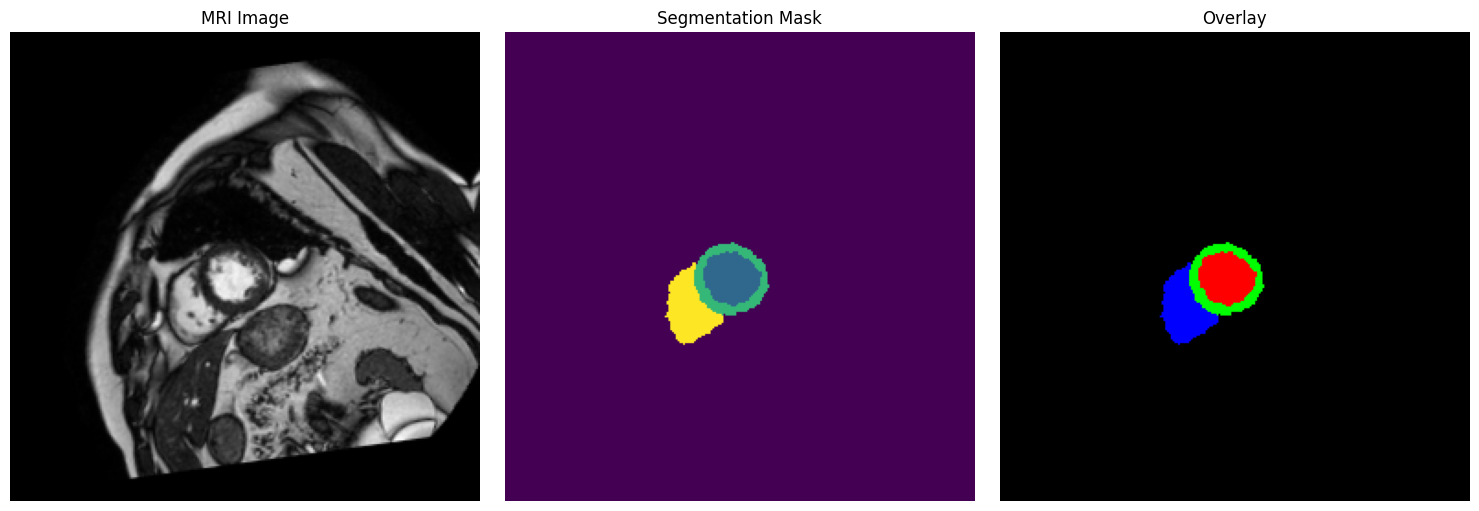


🚀 STARTING MODEL TRAINING


🚀 Training UNet++_EfficientB4
   U-Net++ with EfficientNet-B4 encoder (PRIMARY MODEL)
--------------------------------------------------

Epoch 1/30
    Batch 0/204, Loss: 0.9244, Dice: 0.0506
    Batch 10/204, Loss: 0.8416, Dice: 0.0575
    Batch 20/204, Loss: 0.7940, Dice: 0.0537
    Batch 30/204, Loss: 0.7364, Dice: 0.0866
    Batch 40/204, Loss: 0.7033, Dice: 0.1529
    Batch 50/204, Loss: 0.6945, Dice: 0.1193
    Batch 60/204, Loss: 0.6596, Dice: 0.1903
    Batch 70/204, Loss: 0.6598, Dice: 0.1435
    Batch 80/204, Loss: 0.6238, Dice: 0.2201
    Batch 90/204, Loss: 0.6154, Dice: 0.1625
    Batch 100/204, Loss: 0.5879, Dice: 0.2443
    Batch 110/204, Loss: 0.5829, Dice: 0.2011
    Batch 120/204, Loss: 0.6132, Dice: 0.1907
    Batch 130/204, Loss: 0.5511, Dice: 0.2222
    Batch 140/204, Loss: 0.5348, Dice: 0.3040
    Batch 150/204, Loss: 0.5217, Dice: 0.3022
    Batch 160/204, Loss: 0.5579, Dice: 0.1441
    Batch 170/204, Loss: 0.4977, Dice: 0.3697
    B

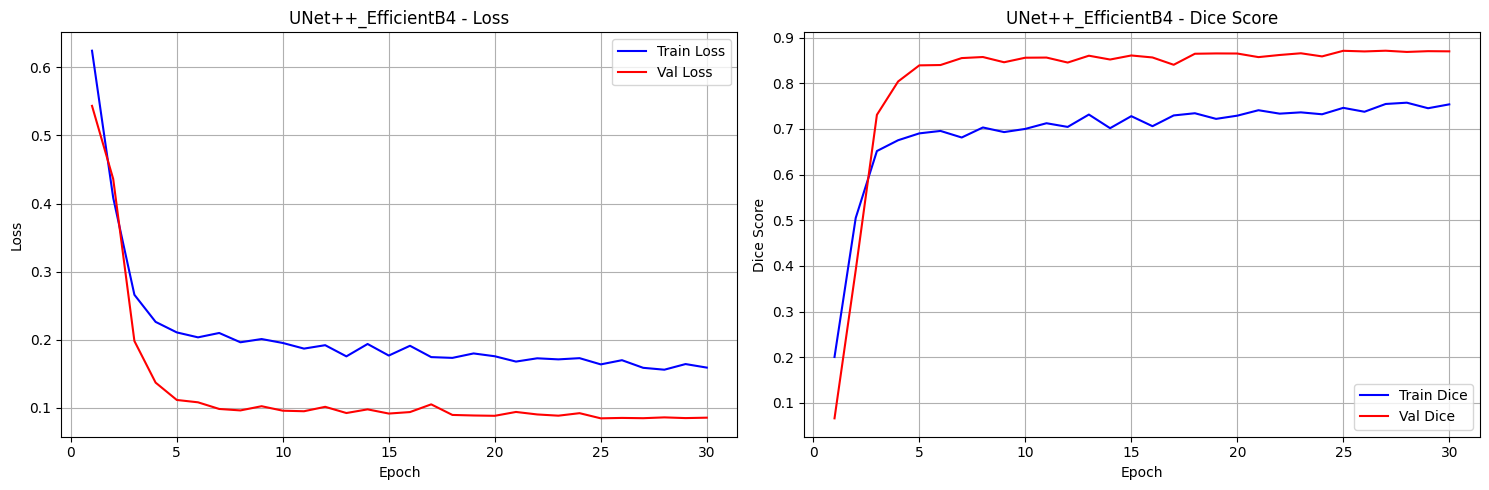



🚀 Training UNet_ResNet34
   Standard U-Net with ResNet34 (baseline)
--------------------------------------------------


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]


Epoch 1/30
    Batch 0/204, Loss: 0.9815, Dice: 0.0246
    Batch 10/204, Loss: 0.8835, Dice: 0.0491
    Batch 20/204, Loss: 0.8201, Dice: 0.0680
    Batch 30/204, Loss: 0.7757, Dice: 0.0617
    Batch 40/204, Loss: 0.7278, Dice: 0.1282
    Batch 50/204, Loss: 0.7109, Dice: 0.1465
    Batch 60/204, Loss: 0.6569, Dice: 0.2708
    Batch 70/204, Loss: 0.6610, Dice: 0.1243
    Batch 80/204, Loss: 0.6267, Dice: 0.1964
    Batch 90/204, Loss: 0.6232, Dice: 0.2064
    Batch 100/204, Loss: 0.6057, Dice: 0.2335
    Batch 110/204, Loss: 0.5702, Dice: 0.2970
    Batch 120/204, Loss: 0.5742, Dice: 0.2945
    Batch 130/204, Loss: 0.5654, Dice: 0.2612
    Batch 140/204, Loss: 0.5708, Dice: 0.1619
    Batch 150/204, Loss: 0.5562, Dice: 0.2410
    Batch 160/204, Loss: 0.5161, Dice: 0.4160
    Batch 170/204, Loss: 0.4922, Dice: 0.4347
    Batch 180/204, Loss: 0.5335, Dice: 0.2653
    Batch 190/204, Loss: 0.4779, Dice: 0.5133
    Batch 200/204, Loss: 0.5430, Dice: 0.2299
  Train Loss: 0.6288, Train Dice:

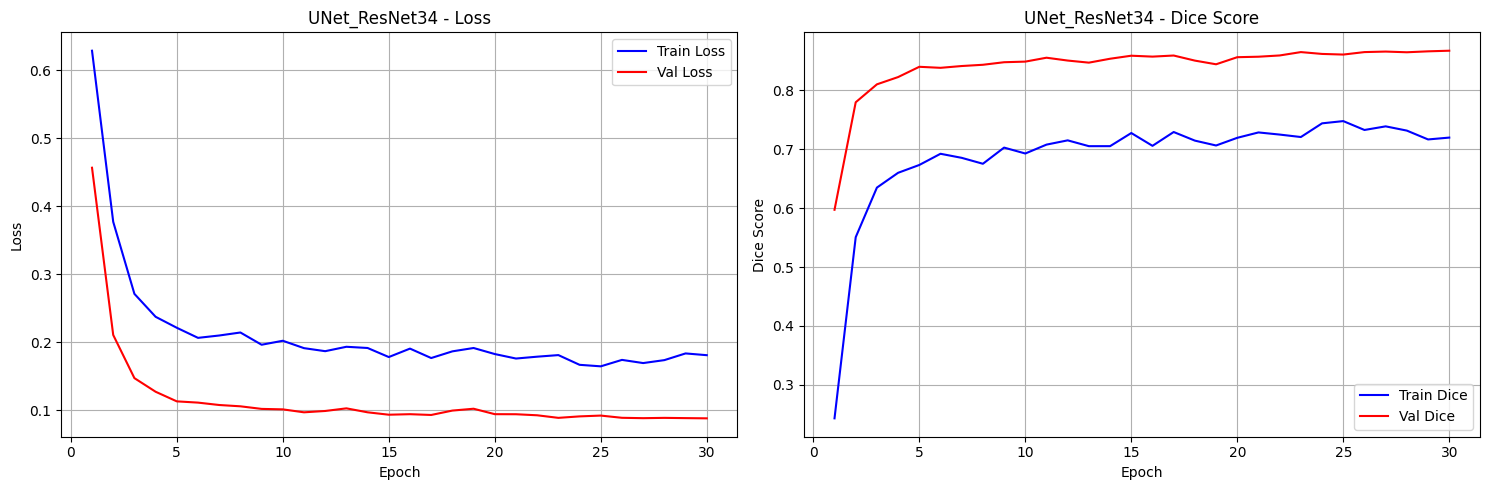


📊 RESULTS ANALYSIS
🏆 MODEL PERFORMANCE RANKING:
             Model Architecture         Encoder  Best_Dice  Final_Train_Loss  Final_Val_Loss  Epochs
UNet++_EfficientB4 UnetPlusPlus efficientnet-b4     0.8713            0.1593          0.0858      30
     UNet_ResNet34         Unet        resnet34     0.8671            0.1808          0.0879      30

🥇 BEST MODEL: UNet++_EfficientB4
   Best Dice Score: 0.8713
   Architecture: UnetPlusPlus + efficientnet-b4

🎉 TRAINING PIPELINE COMPLETED!
Results saved to: /content/drive/MyDrive/Cardiac_Segmentation_Project/results


In [1]:
# ================================================================
# COMPLETE CARDIAC SEGMENTATION TRAINING PIPELINE
# ================================================================

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler, autocast
import segmentation_models_pytorch as smp

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os
import cv2
import nibabel as nib
from sklearn.model_selection import KFold
from sklearn.metrics import confusion_matrix, classification_report

# Image processing and augmentation
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Visualization and monitoring
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

# Suppress warnings
import warnings
warnings.filterwarnings('ignore')

print("COMPLETE CARDIAC SEGMENTATION TRAINING PIPELINE")
print("="*55)

# Check GPU availability
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f" Device: {device}")
if torch.cuda.is_available():
    print(f"   GPU: {torch.cuda.get_device_name(0)}")
    print(f"   Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# ================================================================
# CONFIGURATION
# ================================================================

class CardiacSegmentationConfig:
    """Configuration for cardiac segmentation training"""

    def __init__(self):
        # Data paths
        self.data_root = "/content/drive/MyDrive/Cardiac_Segmentation_Project/data_organized"
        self.train_images_path = os.path.join(self.data_root, 'training/images')
        self.train_labels_path = os.path.join(self.data_root, 'training/labels')
        self.val_images_path = os.path.join(self.data_root, 'validation/images')
        self.val_labels_path = os.path.join(self.data_root, 'validation/labels')
        self.test_images_path = os.path.join(self.data_root, 'testing/images')
        self.test_labels_path = os.path.join(self.data_root, 'testing/labels')

        # Model configuration
        self.image_size = (256, 256)
        self.num_classes = 4  # Background + 3 cardiac structures
        self.in_channels = 1  # Grayscale MRI

        # Training parameters
        self.batch_size = 4  # Reduced for stability
        self.learning_rate = 1e-4
        self.num_epochs = 30  # Reduced for faster training
        self.weight_decay = 1e-5
        self.early_stopping_patience = 8

        # Device configuration
        self.device = device
        self.use_amp = torch.cuda.is_available()

        # Selected pathologies
        self.selected_pathologies = ['NOR', 'LV', 'HCM']

        # Model architectures to compare
        self.model_configs = [
            {
                'name': 'UNet++_EfficientB4',
                'architecture': 'UnetPlusPlus',
                'encoder': 'efficientnet-b4',
                'description': 'U-Net++ with EfficientNet-B4 encoder (PRIMARY MODEL)'
            },
            {
                'name': 'UNet_ResNet34',
                'architecture': 'Unet',
                'encoder': 'resnet34',
                'description': 'Standard U-Net with ResNet34 (baseline)'
            }
        ]

        # Output paths
        self.output_dir = "/content/drive/MyDrive/Cardiac_Segmentation_Project/results"
        os.makedirs(self.output_dir, exist_ok=True)

config = CardiacSegmentationConfig()
print(f"Configuration set: {config.image_size}, {len(config.model_configs)} models")

# ================================================================
# DATASET CLASS
# ================================================================

class CardiacMRIDataset(Dataset):
    """Dataset class for cardiac MRI segmentation"""

    def __init__(self, images_dir, labels_dir, transform=None, config=None):
        self.images_dir = Path(images_dir)
        self.labels_dir = Path(labels_dir)
        self.transform = transform
        self.config = config

        # Get all image files
        self.image_files = sorted([f for f in self.images_dir.glob('*.nii.gz')])

        # Get corresponding label files
        self.valid_pairs = []

        for img_file in self.image_files:
            # Look for corresponding label file
            base_name = img_file.name

            # Try different label naming patterns
            potential_labels = [
                base_name.replace('.nii.gz', '_gt.nii.gz'),
                base_name.replace('_CINE.nii.gz', '_ED_gt.nii.gz'),
                base_name.replace('_ES.nii.gz', '_ES_gt.nii.gz'),
                base_name.replace('_ED.nii.gz', '_ED_gt.nii.gz'),
                base_name.replace('_SA_', '_SA_ED_gt').replace('.nii.gz', '.nii.gz'),
                base_name.replace('_LA_', '_LA_ED_gt').replace('.nii.gz', '.nii.gz')
            ]

            # Also try generic patterns
            subject_id = base_name.split('_')[0]
            potential_labels.extend([
                f"{subject_id}_*_gt.nii.gz"
            ])

            label_found = False
            for potential_label in potential_labels:
                if '*' in potential_label:
                    # Use glob for wildcard patterns
                    matching_labels = list(self.labels_dir.glob(potential_label))
                    if matching_labels:
                        self.valid_pairs.append((img_file, matching_labels[0]))
                        label_found = True
                        break
                else:
                    label_path = self.labels_dir / potential_label
                    if label_path.exists():
                        self.valid_pairs.append((img_file, label_path))
                        label_found = True
                        break

        print(f"Dataset: {len(self.image_files)} images → {len(self.valid_pairs)} valid pairs")

    def __len__(self):
        return len(self.valid_pairs)

    def load_nifti_slice(self, file_path, slice_idx=None):
        """Load a slice from NIfTI file"""
        try:
            nii = nib.load(str(file_path))
            vol = nii.get_fdata()

            # Handle different volume shapes
            if len(vol.shape) == 3:
                if slice_idx is None:
                    slice_idx = vol.shape[2] // 2
                slice_data = vol[:, :, slice_idx]
            elif len(vol.shape) == 4:
                if slice_idx is None:
                    slice_idx = vol.shape[2] // 2
                time_idx = vol.shape[3] // 2
                slice_data = vol[:, :, slice_idx, time_idx]
            else:
                slice_data = vol

            return slice_data.astype(np.float32)

        except Exception as e:
            print(f"Error loading {file_path}: {e}")
            return np.zeros((256, 256), dtype=np.float32)

    def normalize_image(self, image):
        """Normalize image to [0, 1] range"""
        if image.max() > image.min():
            return (image - image.min()) / (image.max() - image.min())
        return image

    def process_mask(self, mask):
        """Process segmentation mask"""
        mask = mask.astype(np.uint8)
        processed_mask = np.zeros_like(mask)

        # Simple mapping
        processed_mask[mask == 1] = 1  # RV
        processed_mask[mask == 2] = 2  # Myocardium
        processed_mask[mask == 3] = 3  # LV

        return processed_mask

    def __getitem__(self, idx):
        img_path, label_path = self.valid_pairs[idx]

        # Load image and mask
        image = self.load_nifti_slice(img_path)
        mask = self.load_nifti_slice(label_path)

        # Normalize image
        image = self.normalize_image(image)

        # Process mask
        mask = self.process_mask(mask)

        # Resize to target size
        image = cv2.resize(image, self.config.image_size, interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, self.config.image_size, interpolation=cv2.INTER_NEAREST)

        # Apply transforms
        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']

        return image.float(), mask.long()

# ================================================================
# DATA AUGMENTATION
# ================================================================

def get_training_augmentation(config):
    """Training augmentations for cardiac MRI"""
    return A.Compose([
        A.Resize(*config.image_size),
        A.HorizontalFlip(p=0.5),
        A.Rotate(limit=10, p=0.5),  # Reduced rotation
        A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.5),
        A.GaussNoise(var_limit=(10.0, 30.0), p=0.3),
        A.Normalize(mean=0.0, std=1.0),
        ToTensorV2(),
    ])

def get_validation_augmentation(config):
    """Validation augmentations (minimal)"""
    return A.Compose([
        A.Resize(*config.image_size),
        A.Normalize(mean=0.0, std=1.0),
        ToTensorV2(),
    ])

# ================================================================
# MODEL FACTORY
# ================================================================

class ModelFactory:
    """Factory to create segmentation models"""

    @staticmethod
    def create_model(config_dict, num_classes=4, in_channels=1):
        architecture = config_dict['architecture']
        encoder_name = config_dict['encoder']

        model_classes = {
            'Unet': smp.Unet,
            'UnetPlusPlus': smp.UnetPlusPlus,
            'DeepLabV3Plus': smp.DeepLabV3Plus,
            'FPN': smp.FPN,
        }

        model = model_classes[architecture](
            encoder_name=encoder_name,
            encoder_weights="imagenet",
            in_channels=in_channels,
            classes=num_classes,
            activation=None
        )

        return model

# ================================================================
# LOSS FUNCTIONS AND METRICS
# ================================================================

class CombinedLoss(nn.Module):
    """Combined Dice + Focal Loss"""

    def __init__(self, alpha=0.7):
        super().__init__()
        self.alpha = alpha
        self.dice_loss = smp.losses.DiceLoss(mode='multiclass')
        self.focal_loss = smp.losses.FocalLoss(mode='multiclass')

    def forward(self, pred, target):
        dice = self.dice_loss(pred, target)
        focal = self.focal_loss(pred, target)
        return self.alpha * dice + (1 - self.alpha) * focal

def calculate_dice_score(pred, target, num_classes=4):
    """Calculate Dice score per class"""
    pred = F.softmax(pred, dim=1)
    pred_classes = torch.argmax(pred, dim=1)

    dice_scores = []
    for class_idx in range(num_classes):
        pred_class = (pred_classes == class_idx).float()
        target_class = (target == class_idx).float()

        intersection = (pred_class * target_class).sum()
        union = pred_class.sum() + target_class.sum()

        if union == 0:
            dice = 1.0
        else:
            dice = (2 * intersection) / union

        dice_scores.append(dice.item())

    return dice_scores, np.mean(dice_scores[1:])  # Exclude background

# ================================================================
# TRAINING FUNCTIONS
# ================================================================

def train_epoch(model, train_loader, optimizer, criterion, device):
    """Train for one epoch"""
    model.train()
    total_loss = 0
    total_dice = 0
    num_batches = 0

    for batch_idx, (images, masks) in enumerate(train_loader):
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        # Calculate metrics
        _, mean_dice = calculate_dice_score(outputs, masks)

        total_loss += loss.item()
        total_dice += mean_dice
        num_batches += 1

        if batch_idx % 10 == 0:
            print(f'    Batch {batch_idx}/{len(train_loader)}, Loss: {loss.item():.4f}, Dice: {mean_dice:.4f}')

    return total_loss / num_batches, total_dice / num_batches

def validate_epoch(model, val_loader, criterion, device):
    """Validate for one epoch"""
    model.eval()
    total_loss = 0
    total_dice = 0
    num_batches = 0

    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)

            outputs = model(images)
            loss = criterion(outputs, masks)

            _, mean_dice = calculate_dice_score(outputs, masks)

            total_loss += loss.item()
            total_dice += mean_dice
            num_batches += 1

    return total_loss / num_batches, total_dice / num_batches

# ================================================================
# MAIN TRAINING FUNCTION
# ================================================================

def train_model(model_config, train_loader, val_loader, config):
    """Train a segmentation model"""

    print(f"\n Training {model_config['name']}")
    print(f"   {model_config['description']}")
    print("-" * 50)

    # Create model
    model = ModelFactory.create_model(
        model_config,
        num_classes=config.num_classes,
        in_channels=config.in_channels
    )
    model = model.to(config.device)

    # Optimizer and scheduler
    optimizer = optim.AdamW(
        model.parameters(),
        lr=config.learning_rate,
        weight_decay=config.weight_decay
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', patience=3, factor=0.5
    )

    # Loss function
    criterion = CombinedLoss()

    # Training history
    history = {
        'train_loss': [],
        'train_dice': [],
        'val_loss': [],
        'val_dice': []
    }

    best_val_dice = 0
    patience_counter = 0

    # Training loop
    for epoch in range(config.num_epochs):
        print(f"\nEpoch {epoch+1}/{config.num_epochs}")

        # Train
        train_loss, train_dice = train_epoch(
            model, train_loader, optimizer, criterion, config.device
        )

        # Validate
        val_loss, val_dice = validate_epoch(
            model, val_loader, criterion, config.device
        )

        # Update scheduler
        scheduler.step(val_loss)

        # Store history
        history['train_loss'].append(train_loss)
        history['train_dice'].append(train_dice)
        history['val_loss'].append(val_loss)
        history['val_dice'].append(val_dice)

        print(f"  Train Loss: {train_loss:.4f}, Train Dice: {train_dice:.4f}")
        print(f"  Val Loss: {val_loss:.4f}, Val Dice: {val_dice:.4f}")

        # Save best model
        if val_dice > best_val_dice:
            best_val_dice = val_dice
            patience_counter = 0
            model_path = os.path.join(config.output_dir, f"best_{model_config['name']}.pth")
            torch.save(model.state_dict(), model_path)
            print(f"  New best model saved! Dice: {val_dice:.4f}")
        else:
            patience_counter += 1

        # Early stopping
        if patience_counter >= config.early_stopping_patience:
            print(f"   Early stopping at epoch {epoch+1}")
            break

    return model, history, best_val_dice

# ================================================================
# CREATE DATASETS AND START TRAINING
# ================================================================

print(f"\n CREATING DATASETS")
print("="*25)

# Create datasets
train_transform = get_training_augmentation(config)
val_transform = get_validation_augmentation(config)

train_dataset = CardiacMRIDataset(
    images_dir=config.train_images_path,
    labels_dir=config.train_labels_path,
    transform=train_transform,
    config=config
)

val_dataset = CardiacMRIDataset(
    images_dir=config.val_images_path,
    labels_dir=config.val_labels_path,
    transform=val_transform,
    config=config
)

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=config.batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=config.batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print(f" Data loaders ready:")
print(f"   Training: {len(train_loader)} batches ({len(train_dataset)} samples)")
print(f"   Validation: {len(val_loader)} batches ({len(val_dataset)} samples)")

# ================================================================
# TEST DATA LOADING
# ================================================================

print(f"\nTESTING DATA LOADING")
print("="*25)

try:
    sample_batch = next(iter(train_loader))
    images, masks = sample_batch

    print(f"Sample batch loaded:")
    print(f"   Images shape: {images.shape}")
    print(f"   Masks shape: {masks.shape}")
    print(f"   Image range: {images.min():.3f} to {images.max():.3f}")
    print(f"   Mask classes: {torch.unique(masks)}")

    # Quick visualization
    def visualize_sample(images, masks, idx=0):
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        img = images[idx, 0].cpu().numpy()
        mask = masks[idx].cpu().numpy()

        axes[0].imshow(img, cmap='gray')
        axes[0].set_title('MRI Image')
        axes[0].axis('off')

        axes[1].imshow(mask, cmap='viridis')
        axes[1].set_title('Segmentation Mask')
        axes[1].axis('off')

        # Overlay
        overlay = np.stack([img, img, img], axis=-1)
        overlay[mask == 1] = [1, 0, 0]  # Red for RV
        overlay[mask == 2] = [0, 1, 0]  # Green for Myocardium
        overlay[mask == 3] = [0, 0, 1]  # Blue for LV

        axes[2].imshow(overlay)
        axes[2].set_title('Overlay')
        axes[2].axis('off')

        plt.tight_layout()
        plt.show()

    visualize_sample(images, masks)

except Exception as e:
    print(f" Error testing data loading: {e}")

# ================================================================
# START MODEL TRAINING
# ================================================================

print(f"\n STARTING MODEL TRAINING")
print("="*30)

all_results = {}

for model_config in config.model_configs:
    try:
        print(f"\n{'='*60}")
        model, history, best_dice = train_model(
            model_config, train_loader, val_loader, config
        )

        all_results[model_config['name']] = {
            'model': model,
            'history': history,
            'best_dice': best_dice,
            'config': model_config
        }

        print(f" {model_config['name']} completed - Best Dice: {best_dice:.4f}")

        # Plot training history
        def plot_history(history, name):
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

            epochs = range(1, len(history['train_loss']) + 1)

            ax1.plot(epochs, history['train_loss'], 'b-', label='Train Loss')
            ax1.plot(epochs, history['val_loss'], 'r-', label='Val Loss')
            ax1.set_title(f'{name} - Loss')
            ax1.set_xlabel('Epoch')
            ax1.set_ylabel('Loss')
            ax1.legend()
            ax1.grid(True)

            ax2.plot(epochs, history['train_dice'], 'b-', label='Train Dice')
            ax2.plot(epochs, history['val_dice'], 'r-', label='Val Dice')
            ax2.set_title(f'{name} - Dice Score')
            ax2.set_xlabel('Epoch')
            ax2.set_ylabel('Dice Score')
            ax2.legend()
            ax2.grid(True)

            plt.tight_layout()
            plt.show()

        plot_history(history, model_config['name'])

    except Exception as e:
        print(f"Error training {model_config['name']}: {e}")
        continue

# ================================================================
# RESULTS ANALYSIS
# ================================================================

print(f"\n RESULTS ANALYSIS")
print("="*20)

if len(all_results) > 0:
    # Create comparison
    comparison_data = []
    for name, results in all_results.items():
        comparison_data.append({
            'Model': name,
            'Architecture': results['config']['architecture'],
            'Encoder': results['config']['encoder'],
            'Best_Dice': results['best_dice'],
            'Final_Train_Loss': results['history']['train_loss'][-1],
            'Final_Val_Loss': results['history']['val_loss'][-1],
            'Epochs': len(results['history']['train_loss'])
        })

    df = pd.DataFrame(comparison_data)
    df = df.sort_values('Best_Dice', ascending=False)

    print("🏆 MODEL PERFORMANCE RANKING:")
    print(df.to_string(index=False, float_format='%.4f'))

    # Save results
    df.to_csv(os.path.join(config.output_dir, "results.csv"), index=False)

    # Best model
    best_model = df.iloc[0]['Model']
    best_dice = df.iloc[0]['Best_Dice']

    print(f"\n BEST MODEL: {best_model}")
    print(f"   Best Dice Score: {best_dice:.4f}")
    print(f"   Architecture: {df.iloc[0]['Architecture']} + {df.iloc[0]['Encoder']}")

else:
    print(" No models completed training successfully")

print(f"\nTRAINING PIPELINE COMPLETED!")
print(f"Results saved to: {config.output_dir}")